We have now downloaded over 100 cutouts of potential detections. We want a way to quickly view them and determine if they are in fact detections.

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.table import Table
from astropy.table import vstack
from astroquery.gaia import Gaia
import tqdm
from astropy.table import join
from scipy.optimize import root_scalar
from astroquery.simbad import Simbad
from ipyaladin import Aladin
from astroquery.casda import Casda
from astropy.coordinates import SkyCoord
from astroquery.utils.tap.core import TapPlus
import astropy.units as u
import anywidget
import ipywidgets
import ipyaladin
import os
import re
import pandas as pd
from pathlib import Path
from astropy.io import fits
from astropy.wcs import WCS
from matplotlib.patches import Rectangle

In [2]:
# Path to the cutouts folder
cutouts_dir = Path("../cutouts")

In [3]:
# Import our FITS data
fits_files = list(cutouts_dir.glob("*.fits"))

# Load them
fits_data = []
fnames = []

for file in fits_files:
    fnames.append(str(file).lstrip('../cutouts/').rstrip('.cont.taylor.0.restored.conv.fits'))
    with fits.open(file) as hdul:
        img = hdul[0].data
        img = np.squeeze(img)
        fits_data.append(img)

Since we are looking for detections/non-detections, we should also have the expected pulse coordinates plotted on our graphs.

In [4]:
sources = Table.read('data/source_obs_data.csv')

In [5]:
ras = sources['Archival_ra']
decs = sources['Archival_dec']
coords = SkyCoord(ra=ras*u.deg, dec=decs*u.deg)
# x, y = WCS.world_to_pixel(coords)

Now we can plot an image and see what it looks like:

Set OBSGEO-B to   -26.704100 from OBSGEO-[XYZ].
Set OBSGEO-H to      121.995 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]


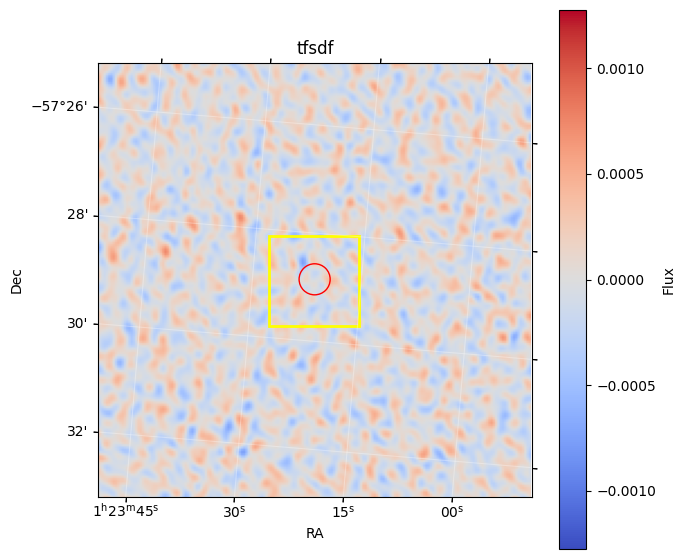

In [18]:
with fits.open(fits_files[0]) as hdul:
    data = np.squeeze(hdul[0].data)
    header = hdul[0].header

wcs = WCS(header).celestial

# Convert all sky coords -> pixel coords
x, y = wcs.world_to_pixel(coords)

fig = plt.figure(figsize=(7,7))
ax = plt.subplot(projection=wcs)

ny, nx = data.shape

# Calculate noise
mask = np.ones_like(data, dtype=bool)
mask[ny//2-20:ny//2+20, nx//2-20:nx//2+20] = False

background = data[mask]

noise = np.nanstd(background)

im = ax.imshow(data, origin="lower", cmap="coolwarm", vmin = -7*noise, vmax = 7*noise)


half = 20

rect = Rectangle(
    (nx//2 - half, ny//2 - half),   # lower-left corner
    2*half, 2*half,                # width, height
    fill=False,
    edgecolor="yellow",
    linewidth=2
)

ax.add_patch(rect)

# Keep only points inside image bounds
inside = (x >= 0) & (x < nx) & (y >= 0) & (y < ny)

ax.scatter(
    x[inside], y[inside],
    s=500, facecolors="none", edgecolors="red"
)

ax.set_xlim(0, nx)
ax.set_ylim(0, ny)

ax.set_xlabel("RA")
ax.set_ylabel("Dec")
ax.grid(color="white", alpha=0.3)

cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Flux")

ax.set_title('tfsdf')

plt.show()

In [10]:
hdul.info()

Filename: ../cutouts/hd___8558_image.v.RACS_0145-56.SB40026.cont.taylor.0.restored.conv.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      86   (193, 193, 1, 1)   float32   


Even if this one was a non-detection in stokes V, we could still have some detections, so lets go ahead and create/save all the images from our cutouts

In [19]:
for file in fits_files:

    # Name for the plot title
    fname = file.stem

    # Import the data
    with fits.open(file) as hdul:
        data = np.squeeze(hdul[0].data)
        header = hdul[0].header
    
    wcs = WCS(header).celestial

    # Calculate noise in data
    rect_size = 20
    ny, nx = data.shape
    mask = np.ones_like(data, dtype=bool)
    mask[ny//2-rect_size:ny//2+rect_size, nx//2-rect_size:nx//2+rect_size] = False
    background = data[mask]
    noise = np.nanstd(background)
        
    # Create plot
    fig = plt.figure(figsize=(7,7))
    ax = plt.subplot(projection=wcs)

    ## Data
    im = ax.imshow(data, origin="lower", cmap="coolwarm", vmin = -7*noise, vmax = 7*noise)

    ## Mask bounds
    rect = Rectangle((nx//2 - rect_size, ny//2 - rect_size), 2*rect_size, 2*rect_size, fill=False, edgecolor="yellow", linewidth=2)
    ax.add_patch(rect)

    ## Make it prettier
    ax.set_xlim(0, nx)
    ax.set_ylim(0, ny)
    
    ax.set_xlabel("RA")
    ax.set_ylabel("Dec")
    ax.grid(color="white", alpha=0.3)
    
    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label("Flux")
    
    ax.set_title(fname)
    fig.tight_layout()
    
    fig.savefig(f"../cutouts/images/{fname}.png", dpi=150)
    plt.close(fig)

Set OBSGEO-B to   -26.704100 from OBSGEO-[XYZ].
Set OBSGEO-H to      121.995 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set OBSGEO-B to   -26.704100 from OBSGEO-[XYZ].
Set OBSGEO-H to      121.995 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set OBSGEO-B to   -26.704100 from OBSGEO-[XYZ].
Set OBSGEO-H to      121.995 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set OBSGEO-B to   -26.704100 from OBSGEO-[XYZ].
Set OBSGEO-H to      121.995 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set OBSGEO-B to   -26.704100 from OBSGEO-[XYZ].
Set OBSGEO-H to      121.995 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set OBSGEO-B to   -26.704100 from OBSGEO-[XYZ].
Set OBSGEO-H to      121.995 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set OBSGEO-B to   -26.704100 from OBSGEO-[XYZ].
Set OBSGEO-H to      121.995 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set OBSGEO-B to   -26.704100 from OBSGEO-[XYZ].
Set OBSGEO-H to      121.995 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set OBSGEO-B to   -26.704100 from OBSGEO-[XYZ].
Set OBSGEO-H to      121.995 fro